# 01 — Exploration des données

**Objectif :** comprendre les données avant de modéliser. On vérifie :
1. la répartition tricheurs / honnêtes (déséquilibre des classes) ;
2. les variables qui distinguent les tricheurs ;
3. les **pièges d'équité** identifiés dans le cahier des charges (manette, accessibilité) ;
4. pourquoi la règle actuelle « trier par signalements » est insuffisante ;
5. la qualité des données (valeurs manquantes, contrat).

Les données sont synthétiques et générées par `src/data/generate.py` (graine fixe : reproductibles).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Permet d'importer le code du dossier src/ depuis le dossier notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.viz import BLUE, HONEST_CHEATER_COLORS, HONEST_CHEATER_LABELS, ORANGE, apply_style

apply_style()
pd.set_option("display.precision", 3)

In [2]:
from src.config import NUMERIC_FEATURES, TARGET
from src.data.generate import generate_dataset
from src.data.validate import validate_dataset

df = generate_dataset(n_matches=50_000, seed=42)
validate_dataset(df)  # lève une erreur claire si le contrat de données n'est pas respecté
print(f"{len(df):,} fiches (joueur, match) — {df['player_id'].nunique():,} joueurs")
df.head()

50,000 fiches (joueur, match) — 8,315 joueurs


,player_id,match_id,match_date,accuracy,headshot_rate,kd_ratio,kills_per_min,damage_per_round,avg_reaction_ms,kills_through_smoke_ratio,rank_tier,account_age_days,hours_played_total,reports_received,input_device,platform,age_band,accessibility_mode,is_cheater
0,f0123aff-35fb-4605-9dc7-a3e7c610f393,c861a940-6109-4a36-80b5-cc7fe6b2edae,2026-08-09,0.316,0.412,1.07,0.90,158.3,196.1,0.000,7,1212,1793.5,0,clavier_souris,pc,18-24,False,0
1,39422538-868c-457f-ba8c-4bc62da3c718,1a417356-cb5c-4033-9ea5-1c8b25f9f7c3,2026-09-01,0.332,0.269,0.78,0.61,161.3,229.6,0.026,6,89,85.5,0,clavier_souris,pc,35+,False,0
2,bd0c6a0f-b557-4da2-a06d-4b653d40b123,9abc17af-4c73-4a8d-b547-ac852812df4b,2026-08-01,0.238,0.263,0.96,0.89,143.7,314.5,0.022,5,346,374.1,1,clavier_souris,pc,16-17,False,0
3,df80b95f-b7c2-48ee-aaf7-9fc07d09d7e8,79d91b74-5bae-4cae-994f-affc5b6e2d2b,2026-09-28,0.350,0.344,1.34,0.77,139.4,336.2,0.005,2,259,210.8,2,manette,console,25-34,True,0
4,ff7bc830-a539-43bd-baec-7004ac2f4694,3a2fb402-2dd8-4fe6-8738-d638c8f779f0,2026-08-15,0.195,0.257,0.66,0.56,72.2,283.0,0.017,4,108,157.8,1,clavier_souris,pc,18-24,False,0


## 1. Déséquilibre des classes

In [3]:
counts = df[TARGET].value_counts().rename(index=HONEST_CHEATER_LABELS)
print(counts.to_string())
print(f"\nPart de tricheurs : {df[TARGET].mean():.1%}")

is_cheater
Honnêtes     48579
Tricheurs     1421

Part de tricheurs : 2.8%


Environ **3 % de tricheurs** : un modèle qui répondrait toujours « honnête » aurait 97 % de bonnes réponses tout en étant inutile.
➡️ On n'utilisera **pas l'accuracy**, mais la PR-AUC, la précision sur les cas les plus suspects et le taux de faux positifs (voir notebook 02).

## 2. Les signaux de triche

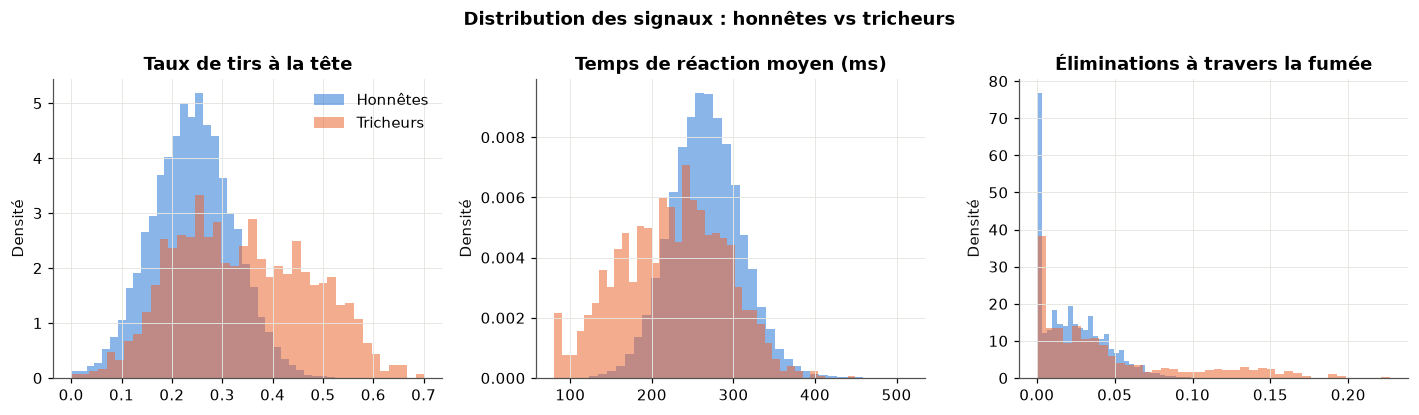

In [4]:
signals = [
    ("headshot_rate", "Taux de tirs à la tête"),
    ("avg_reaction_ms", "Temps de réaction moyen (ms)"),
    ("kills_through_smoke_ratio", "Éliminations à travers la fumée"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (column, title) in zip(axes, signals):
    for label in (0, 1):
        values = df.loc[df[TARGET] == label, column].dropna()
        ax.hist(
            values,
            bins=40,
            density=True,
            alpha=0.55,
            color=HONEST_CHEATER_COLORS[label],
            label=HONEST_CHEATER_LABELS[label],
        )
    ax.set_title(title)
    ax.set_ylabel("Densité")
axes[0].legend()
fig.suptitle("Distribution des signaux : honnêtes vs tricheurs", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
df.groupby(TARGET)[NUMERIC_FEATURES].median().rename(index=HONEST_CHEATER_LABELS).T

is_cheater,Honnêtes,Tricheurs
accuracy,0.258,0.304
headshot_rate,0.241,0.333
kd_ratio,1.090,1.480
kills_per_min,0.700,0.910
damage_per_round,130.300,155.300
avg_reaction_ms,265.500,227.600
kills_through_smoke_ratio,0.020,0.028
rank_tier,4.000,5.000
account_age_days,266.000,127.000
hours_played_total,217.600,96.400


**Lecture :** les tricheurs visent plus souvent la tête, réagissent plus vite et éliminent plus à travers la fumée.
Mais les distributions **se chevauchent fortement** : de nombreux tricheurs « discrets » ressemblent à des honnêtes, et des honnêtes très doués ressemblent à des tricheurs. Aucune variable seule ne suffit → il faut un modèle qui combine les signaux.

## 3. Piège d'équité n°1 : l'assistance à la visée de la manette

                accuracy  headshot_rate
input_device                           
clavier_souris     0.241          0.252
manette            0.290          0.220


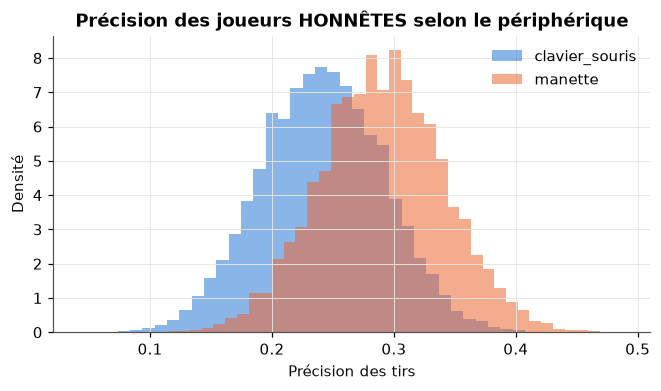

In [6]:
honest = df[df[TARGET] == 0]
by_device = honest.groupby("input_device")[["accuracy", "headshot_rate"]].mean()
print(by_device.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
for color, (device, rows) in zip([BLUE, ORANGE], honest.groupby("input_device")):
    ax.hist(rows["accuracy"], bins=40, density=True, alpha=0.55, color=color, label=device)
ax.set_title("Précision des joueurs HONNÊTES selon le périphérique")
ax.set_xlabel("Précision des tirs")
ax.set_ylabel("Densité")
ax.legend()
plt.show()

Les joueurs **honnêtes** à la manette sont **plus précis** (assistance à la visée intégrée au jeu).
➡️ Risque : un modèle naïf pourrait les soupçonner à tort. C'est pourquoi `input_device` est fourni au modèle (pour qu'il « sache » qu'une forte précision est normale à la manette) et pourquoi le taux de faux positifs est audité par périphérique (notebook 03).

## 4. Piège d'équité n°2 : l'option d'accessibilité

In [7]:
honest.groupby("accessibility_mode")["avg_reaction_ms"].describe()[["mean", "std"]].round(1)

,mean,std
accessibility_mode,,
False,264.6,41.1
True,306.7,71.9


Les joueurs qui utilisent l'option d'accessibilité ont des temps de réaction **plus longs et plus variables**.
Cette variable est un **réglage technique**, **jamais utilisée par le modèle** : elle sert uniquement à vérifier, de façon agrégée, que ces joueurs ne sont pas pénalisés (cahier des charges, section 8).

## 5. Pourquoi « trier par signalements » ne suffit pas

In [8]:
table = df.groupby("reports_received")[TARGET].agg(["count", "mean"]).head(8)
table.columns = ["Nombre de fiches", "Part de tricheurs"]
print(table.round(3).to_string())

quartiles = ["Q1", "Q2", "Q3", "Q4 (meilleurs)"]
talent = honest.assign(niveau=pd.qcut(honest["kd_ratio"], 4, labels=quartiles))
print("\nSignalements moyens des joueurs HONNÊTES selon leur ratio éliminations/morts :")
print(talent.groupby("niveau", observed=True)["reports_received"].mean().round(2).to_string())

                  Nombre de fiches  Part de tricheurs
reports_received                                     
0                            25739              0.015
1                            16485              0.025
2                             5919              0.050
3                             1469              0.125
4                              292              0.312
5                               72              0.472
6                               18              0.944
7                                4              1.000

Signalements moyens des joueurs HONNÊTES selon leur ratio éliminations/morts :
niveau
Q1                0.50
Q2                0.59
Q3                0.70
Q4 (meilleurs)    0.87


Les signalements augmentent bien avec la triche, mais **les meilleurs joueurs honnêtes sont aussi beaucoup signalés** (adversaires frustrés).
➡️ La règle actuelle confond talent et triche : c'est le problème métier que Sentinel doit résoudre.

## 6. Qualité des données

In [9]:
missing = df.isna().mean().loc[lambda s: s > 0]
print("Part de valeurs manquantes :")
print(missing.map("{:.1%}".format).to_string())

Part de valeurs manquantes :
avg_reaction_ms    2.1%


Seul le temps de réaction comporte des valeurs manquantes (~2 %, perte de télémétrie simulée). Elles sont **autorisées par le contrat** et remplacées par la médiane dans le pipeline du modèle (`src/features.py`).

## Conclusions
- Classes très déséquilibrées → métriques adaptées (PR-AUC, précision sur le top 1 %, faux positifs).
- Signaux réels mais chevauchants → modèle combinant plusieurs variables.
- Deux pièges d'équité confirmés → audit obligatoire (notebook 03).
- La règle des signalements confond talent et triche → référence à battre (notebook 02).